# Tennis CSV → official MulTaBench: Colab smoke test

**Open this notebook, select Runtime → Change runtime type → A100 GPU (high RAM if available), then Run all.**
The first run installs the official pinned dependencies in a separate Python 3.11 environment and downloads E5 weights.
If Drive saving is enabled, approve Google's Drive mount prompt. Installation may take longer than this tiny evaluation.
[Colab documentation](https://research.google.com/colaboratory/faq.html) describes GPU availability and runtime limits.

Default: **LightGBM × four conditions × one holdout = four runs**, with two TAR epochs.
Their model classes, E5/PCA preprocessing, split functions and AUROC scoring are used unchanged.
Our code only supplies the CSV, chooses predictor columns, schedules calls and displays returned results.
Their original CLI logs to Weights & Biases; this notebook uses their returned summary dictionary, so no W&B account is required.

**This is a plumbing test, not the final tennis dataset.** Its 488 Kaggle matches have generated past-results summaries,
not expert tactical articles. A positive gain here does not establish project passage or choose tennis.
Only the data-preview cells have been executed locally. The Colab install, checkpoint access and model fits remain to be tested.


In [ ]:
# Configuration: keep these defaults for the first run.
MODE = "smoke"  # smoke: one learner / one fold / 2 TAR epochs.
# diagnostic: all five learners / one fold / official 50-epoch TAR maximum.
# full: all five learners / five folds; rejects the supplied smoke fixture.
SAVE_TO_DRIVE = True  # Preserves completed results across Colab runtime resets.
AUTO_STOP_RUNTIME = True  # Final cell disconnects/deletes the VM after Drive export.
if AUTO_STOP_RUNTIME and not SAVE_TO_DRIVE:
    raise ValueError("Automatic shutdown requires Drive saving. Otherwise set AUTO_STOP_RUNTIME=False.")
PAPER_COMMIT = "3bb95079a6146ed35d45187e98bcad5b063273a1"
DATA_REL = "research/data/tennis_smoke/tennis_smoke.csv"
SCHEMA_REL = "research/data/tennis_smoke/schema.json"
# Optional: evaluate a candidate built elsewhere (e.g. notebook 06 writes VAERS to Drive).
# Example: CSV_PATH = "/content/drive/MyDrive/text-tabular-research-2/candidates/vaers_v1/vaers_v1.csv"
CSV_PATH = None
SCHEMA_PATH = None  # The schema.json written next to CSV_PATH.
# Optional learner subset for a cheap screen, e.g. ["light", "cat"] with MODE = "diagnostic".
MODELS_OVERRIDE = None


## 1. Get our files and the separate, unchanged reference

The complete official checkout is created only in this Colab VM at `/content/MulTaBench-reference`.
It is outside our project repository and pinned to the audited `paper_version` commit.
The small historical source files under `research/data/sources` are reading material; they are not the executable benchmark.

Official repository: [alanarazi7/MulTaBench](https://github.com/alanarazi7/MulTaBench).
Exact version: [paper-version commit 3bb9507](https://github.com/alanarazi7/MulTaBench/tree/3bb95079a6146ed35d45187e98bcad5b063273a1).
The official README recommends `paper_version` or `official-paper-version` for reproducing the paper;
current `master` is a changing leaderboard and also has newer `sweep.py` / `collect_results.py` tools.
Those newer tools are not the interface of our pinned paper version.


In [ ]:
from pathlib import Path
import os, sys, subprocess, json, hashlib

if not Path("/content").exists():
    raise RuntimeError("Run this notebook in Google Colab; no local benchmark installation is needed.")
PROJECT = Path("/content/text-tabular-research-2")
REFERENCE = Path("/content/MulTaBench-reference")
ENV = Path("/content/multabench-env")

def command(args, **kwargs):
    # This bootstrap runs before our logging helper can be imported.
    # Capture explicitly: inherited child stderr may be hidden by Colab.
    args = list(map(str, args))
    print(" ".join(args), flush=True)
    result = subprocess.run(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, **kwargs)
    print(result.stdout, end="", flush=True)
    if result.returncode:
        raise RuntimeError(f"Command failed (exit {result.returncode}). Full error above:\n{result.stdout}")
    return result

if not PROJECT.exists():
    command(["git", "clone", "--depth", "1", "https://github.com/DimaBsharaa/text-tabular-research-2.git", PROJECT])
else:
    command(["git", "-C", PROJECT, "pull", "--ff-only"])  # Refresh our adapter; never alter the official checkout.
if not REFERENCE.exists():
    command(["git", "clone", "--depth", "1", "--branch", "paper_version", "https://github.com/alanarazi7/MulTaBench.git", REFERENCE])
head = subprocess.check_output(["git", "-C", str(REFERENCE), "rev-parse", "HEAD"], text=True).strip()
if head != PAPER_COMMIT:
    if subprocess.check_output(["git", "-C", str(REFERENCE), "status", "--porcelain"], text=True).strip():
        raise RuntimeError("Reference has local changes; use a fresh Colab runtime.")
    command(["git", "-C", REFERENCE, "fetch", "--depth", "1", "origin", PAPER_COMMIT])
    command(["git", "-C", REFERENCE, "checkout", "--detach", PAPER_COMMIT])
sys.path.insert(0, str(PROJECT))  # Dashboard helpers only; models run in the isolated environment.
from evaluation.colab_session import run_logged_command
command = run_logged_command  # Explicitly stream child stdout AND stderr into cell output.
if (CSV_PATH is None) != (SCHEMA_PATH is None):
    raise ValueError("Set both CSV_PATH and SCHEMA_PATH, or neither")
if CSV_PATH and str(CSV_PATH).startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
CSV = Path(CSV_PATH) if CSV_PATH else PROJECT / DATA_REL
SCHEMA = Path(SCHEMA_PATH) if SCHEMA_PATH else PROJECT / SCHEMA_REL
assert CSV.exists() and SCHEMA.exists(), f"Missing data: {CSV} / {SCHEMA}"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
print("Our commit:", subprocess.check_output(["git", "-C", str(PROJECT), "rev-parse", "HEAD"], text=True).strip())
print("Official reference:", PAPER_COMMIT)


### 1a. What “unchanged official code” means — and the evidence

**This notebook is ours, not a 1:1 copy of an official notebook.** Its CSV loader, scheduling and dashboard are ours.
The evaluator, learner wrappers, embedding/fine-tuning code, PCA and metrics are imported from their unchanged checkout.
Smoke parameters are deliberately different: one learner, one holdout and two TAR epochs (batch 32).
Official TAR defaults are up to 50 epochs (batch 256). Therefore this smoke test is not a full paper reproduction.

| Official file/folder | What they provide |
| --- | --- |
| `benchmark.py` | CLI for one registered dataset/model/condition/fold; paper-version W&B logging. |
| `multabench/baselines/benchmarks/evaluate.py` | Samples, splits, constructs the learner, fits and scores it. This is the function our CSV adapter calls. |
| `multabench/baselines/{lgbm,catboost,tabm,tabpfnv2}.py` | The five required learner wrappers; both TabPFN versions are in `tabpfnv2.py`. |
| `multabench/baselines/abstract_model.py` | Shared training/validation and preprocessing flow. |
| `multabench/baselines/preprocessing/` | Numerical/categorical handling, text encoders and per-column PCA. |
| `multabench/e5/`, `multabench/finetune/` | E5 encoding, target-aware LoRA adaptation and default training arguments. |
| `multabench/baselines/training/metrics.py` | AUROC and regression metrics. |
| `multabench/datasets/`, `multabench/benchmark/` | Dataset registry, downloading, curation recipes and historical benchmark artifacts. |
| `multabench/dino/` | Image encoders for image-tabular tasks, not our text-only modality experiment. |
| `requirements.txt`, `init.sh`, `.env.example`, `README.md` | Dependency pins, setup, credentials template and documentation. |

The next cell needs only Python and Git: it verifies the official remote, exact commit and **every tracked file's bytes**
against the Git objects at that commit, then displays hashes and direct links for the relevant source files.
It stops on a mismatch. Later the worker also prints where the actually imported modules came from and saves that evidence.
TabSTAR split helpers are an external pinned dependency (`tabstar==1.1.15`), not source files in this checkout.
Source identity does not prove package compatibility, checkpoint access, or identical scores; those need runtime validation.


In [ ]:
from evaluation.colab_runner import verify_reference, worker_environment
import pandas as pd
from IPython.display import display

reference_files = verify_reference(REFERENCE)
IMPORTANT_FILES = ["benchmark.py", "multabench/baselines/benchmarks/evaluate.py",
    "multabench/baselines/abstract_model.py", "multabench/baselines/lgbm.py",
    "multabench/baselines/catboost.py", "multabench/baselines/tabm.py",
    "multabench/baselines/tabpfnv2.py", "multabench/baselines/preprocessing/text_embeddings.py",
    "multabench/e5/e5_finetune.py", "multabench/finetune/train_args.py",
    "multabench/baselines/training/metrics.py", "requirements.txt"]
source_table = pd.DataFrame(reference_files)
source_table = source_table[source_table.path.isin(IMPORTANT_FILES)].copy()
source_table["official_url"] = source_table.path.map(lambda p: f"https://github.com/alanarazi7/MulTaBench/blob/{PAPER_COMMIT}/{p}")
assert len(source_table) == len(IMPORTANT_FILES)
display(source_table[["path", "matches_commit", "sha256", "official_url"]])
print(f"PASS: all {len(reference_files)} tracked files match the pinned official Git blobs.")
print("This output verifies source identity, not completed training or full experimental equivalence.")


## 2. Inspect the prepared CSV

Source: [Kaggle daily ATP data](https://www.kaggle.com/datasets/dissfya/atp-tennis-2000-2023daily-pull), version 1219.
This uses only complete rows from the previously inspected 64 KiB prefix; the full file is not downloaded here.
A/B orientation uses a fixed hash of match identity and an unordered pair of player names, independent of the winner.
Current winner/score/odds, identities and provenance are excluded from predictors.
Histories update after an entire date has been processed, so same-day outcomes cannot enter features.
The source's abbreviated identifiers, ranking availability and reported dates still need auditing for a real forecasting dataset.


,value
Rows,488
Player A win fraction,0.485656
Earliest date,2000-01-03
Latest date,2000-02-21
Structured features,13
Text fields,2
A distinct texts,341
B distinct texts,341


,match_date,player_a,player_b,a_rank,b_rank,player_a_wins
0,2000-01-03,Arthurs W.,Gambill J.M.,105.0,58.0,0
1,2000-01-03,Baccanello P.,Escude N.,655.0,40.0,0
2,2000-01-03,Balcells J.,Henman T.,218.0,11.0,0
3,2000-01-03,Clement A.,Enqvist T.,56.0,5.0,0
4,2000-01-03,Ljubicic I.,Dosedel S.,77.0,63.0,0
5,2000-01-03,Draper S.,Norman M.,155.0,15.0,0
6,2000-01-03,Knippschild J.,Federer R.,87.0,65.0,0
7,2000-01-03,Woodbridge T.,Fromberg R.,198.0,81.0,0


Example temporary text:
 Earlier recorded results for Squillari F.: 1 wins in 2 matches. On Hard, 1 wins in 2 earlier matches. On 2000-01-03, Squillari F. won against Siemerink J. on Hard at Qatar Open. On 2000-01-03, Squillari F. lost against Schalken S. on Hard at Qatar Open. This statistical summary provides no injury or tactical assessment.


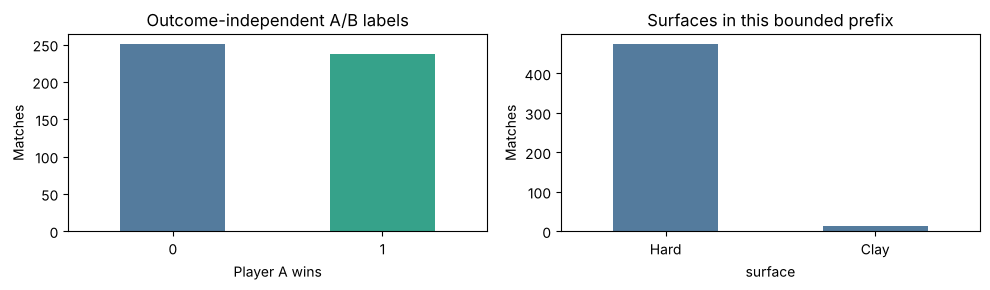

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

schema = json.loads(SCHEMA.read_text())
df = pd.read_csv(CSV)
assert hashlib.sha256(CSV.read_bytes()).hexdigest() == schema["csv_sha256"]
TENNIS_FIXTURE = schema["target"] == "player_a_wins"
if not TENNIS_FIXTURE:  # Generic candidate preview (e.g. VAERS); the tennis-specific cells below are skipped.
    tgt = schema["target"]
    display(pd.DataFrame({"value": {"Rows": len(df), f"{tgt} = 1 fraction": round(df[tgt].mean(), 4),
        "Structured features": len(schema["structured_columns"]), "Text fields": len(schema["text_columns"])}}))
    display(pd.DataFrame({c: {"distinct": df[c].nunique(), "mean chars": round(df[c].astype(str).str.len().mean(), 1)}
                          for c in schema["text_columns"]}).T)
    display(df[schema["structured_columns"] + schema["text_columns"] + [tgt]].head(5))
    print("Audit columns excluded from X:", schema["audit_columns"])
if TENNIS_FIXTURE:
    display(pd.DataFrame({"value": {"Rows": len(df), "Player A win fraction": df.player_a_wins.mean(),
        "Earliest date": df.match_date.min(), "Latest date": df.match_date.max(),
        "Structured features": len(schema["structured_columns"]), "Text fields": len(schema["text_columns"]),
        "A distinct texts": df.player_a_text.nunique(), "B distinct texts": df.player_b_text.nunique()}}))
    display(df[["match_date", "player_a", "player_b", "a_rank", "b_rank", "player_a_wins"]].head(8))
    print("Example temporary text:\n", df.loc[df.a_prior_matches > 0, "player_a_text"].iloc[0])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    df.player_a_wins.value_counts().reindex([0, 1]).plot.bar(ax=axes[0], color=["#547b9d", "#36a28a"], rot=0)
    axes[0].set(xlabel="Player A wins", ylabel="Matches", title="Outcome-independent A/B labels")
    df.surface.value_counts().plot.bar(ax=axes[1], rot=0, color="#547b9d")
    axes[1].set(ylabel="Matches", title="Surfaces in this bounded prefix")
    plt.tight_layout(); plt.show()


**Insight:** The label count is a useful check against accidentally making A the winner on every row.
This prefix covers a short early-2000 period, so its surface mix and balance describe only the fixture.
They do not estimate modern ATP coverage or text availability. The temporary prose deliberately restates historical results.


,side,rows_without_earlier_history,history_timing_violations
0,A,177,0
1,B,165,0


Audit columns excluded from X: ['match_id', 'match_date', 'player_a', 'player_b', 'a_history_last_date', 'b_history_last_date']
Structured X: ['surface', 'court', 'tournament_level', 'round', 'best_of', 'a_rank', 'b_rank', 'a_prior_matches', 'b_prior_matches', 'a_prior_winrate', 'b_prior_winrate', 'a_surface_winrate', 'b_surface_winrate']
Text X: ['player_a_text', 'player_b_text']


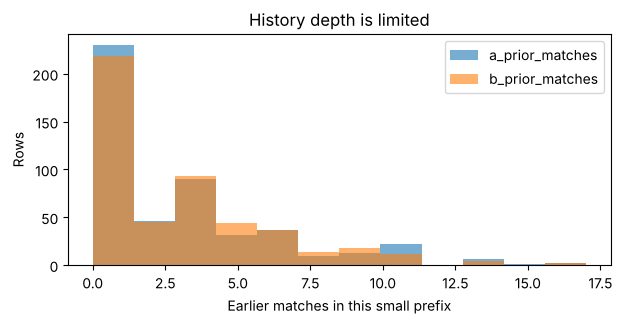

In [2]:
if TENNIS_FIXTURE:  # Tennis-fixture timing checks only.
    check_rows = []
    for side in ["a", "b"]:
        last = df[f"{side}_history_last_date"].fillna("")
        assert ((last == "") | (last < df.match_date)).all()
        check_rows.append({"side": side.upper(), "rows_without_earlier_history": int((df[f"{side}_prior_matches"] == 0).sum()),
                           "history_timing_violations": int(((last != "") & (last >= df.match_date)).sum())})
    display(pd.DataFrame(check_rows))
    print("Audit columns excluded from X:", schema["audit_columns"])
    print("Structured X:", schema["structured_columns"])
    print("Text X:", schema["text_columns"])
    df[["a_prior_matches", "b_prior_matches"]].plot.hist(bins=12, alpha=.6, figsize=(7, 3))
    plt.xlabel("Earlier matches in this small prefix"); plt.ylabel("Rows"); plt.title("History depth is limited"); plt.show()


**Insight:** Empty early histories are expected because the source prefix starts in January 2000.
Zero timing violations verify the construction rule, not the external accuracy of the dates.
A real tennis dataset would require broader history and historical availability checks.


## 3. Install their exact environment outside the checkout

The official `requirements.txt` is large because it includes other benchmark models too.
We use it unchanged in an isolated Python 3.11 environment rather than replacing Colab's notebook packages.
The official `init.sh` is not run: it also changes host Python/shell configuration.
If installation fails, keep its log and resolve the environment before training; no dependency pins are silently relaxed.


In [ ]:
command([sys.executable, "-m", "pip", "install", "uv"])
UV = [sys.executable, "-m", "uv"]
if not (ENV / "bin/python").exists():
    command(UV + ["python", "install", "3.11"])
    command(UV + ["venv", "--python", "3.11", "--seed", str(ENV)])
BENCH_PY = ENV / "bin/python"
install_env = {**os.environ, "UV_HTTP_TIMEOUT": "120"}
command(UV + ["pip", "install", "--python", str(BENCH_PY), "-r", str(REFERENCE / "requirements.txt")], env=install_env)
command([BENCH_PY, "-m", "pip", "check"])
command([BENCH_PY, "-c", "import torch; print('Torch:', torch.__version__); print('CUDA:', torch.cuda.is_available()); assert torch.cuda.is_available(), 'Select GPU runtime'; print('GPU:', torch.cuda.get_device_name(0))"])


## 4. Persistent outputs and optional TabPFN access

Each completed condition is saved immediately and reused on an identical rerun.
Drive saving keeps results after the Colab VM is deleted. With it disabled, download the ZIP at the end before disconnecting.
The first LightGBM smoke test needs no private token. For TabPFN later, add `HF_TOKEN` to Colab Secrets and grant notebook access,
with any required model permissions accepted on Hugging Face. Import checks alone do not validate checkpoint access.


In [ ]:
if MODE not in {"smoke", "diagnostic", "full"}:
    raise ValueError(MODE)
if MODE == "full" and schema.get("purpose") != "candidate_dataset":
    raise ValueError("This CSV is a smoke fixture. Choose a real curated candidate before full evaluation.")
MODELS = ["light"] if MODE == "smoke" else ["light", "cat", "tabm", "tabpfnv2", "tabpfnv2p5"]
if MODELS_OVERRIDE:
    if MODE == "full":
        raise ValueError("Full evaluation must run all five learners")
    assert set(MODELS_OVERRIDE) <= {"light", "cat", "tabm", "tabpfnv2", "tabpfnv2p5"}, MODELS_OVERRIDE
    MODELS = list(MODELS_OVERRIDE)
FOLDS = [0] if MODE != "full" else [0, 1, 2, 3, 4]
CONDITIONS = ["structured_only", "text_only", "joint_frozen", "joint_tar"]
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception:
    token = None
if token:
    os.environ["HF_TOKEN"] = token  # Never printed or saved in artifacts.
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    output_base = Path("/content/drive/MyDrive/text-tabular-research-2/benchmark-results")
else:
    output_base = Path("/content/tennis-benchmark-results")
plan = {"mode": MODE, "models": MODELS, "folds": FOLDS, "conditions": CONDITIONS,
        "csv_sha256": schema["csv_sha256"], "benchmark_commit": PAPER_COMMIT,
        "adapter_sha256": hashlib.sha256((PROJECT / "evaluation/colab_runner.py").read_bytes()).hexdigest(),
        "environment_sha256": hashlib.sha256(subprocess.check_output([str(BENCH_PY), "-m", "pip", "freeze"])).hexdigest()}
plan_id = hashlib.sha256(json.dumps(plan, sort_keys=True).encode()).hexdigest()[:16]
OUTPUT = output_base / plan_id
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "plan.json").write_text(json.dumps(plan, indent=2))
COMMON = [str(BENCH_PY), "-u", str(PROJECT / "evaluation/colab_runner.py"),
          "--reference", str(REFERENCE), "--csv", str(CSV), "--schema", str(SCHEMA),
          "--output", str(OUTPUT), "--mode", MODE, "--train-examples", "10000"]
print(f"{MODE}: {len(MODELS) * len(FOLDS) * 4} runs; results: {OUTPUT}")
WORKER_ENV = worker_environment()  # A copy; notebook inline plotting is unchanged.
command(COMMON + ["--model", "light", "--condition", "joint_tar", "--check"],
        log_path=OUTPUT / "preflight.log", env=WORKER_ENV)
source_proof = json.loads((OUTPUT / "reference_proof.json").read_text())
loaded = pd.DataFrame(source_proof["imported_modules"])
key_modules = ["multabench.baselines.benchmarks.evaluate", "multabench.baselines.abstract_model",
               "multabench.baselines.lgbm", "multabench.baselines.catboost", "multabench.baselines.tabm",
               "multabench.baselines.tabpfnv2", "multabench.baselines.preprocessing.text_embeddings",
               "multabench.e5.e5_finetune", "multabench.baselines.training.metrics"]
display(loaded[loaded.module.isin(key_modules)][["module", "loaded_from", "matches_commit"]])
assert set(key_modules) <= set(loaded.module)
print("The actually imported evaluator and model modules came from the verified official checkout.")


**If preflight fails:** read the worker traceback printed above the final `CalledProcessError`.
The same output is saved to `preflight.log` in the displayed Drive results folder; `preflight_error.json` also records Python errors.
Training has not started. Fix the reported cause and rerun this cell. The final automatic shutdown runs only if execution reaches it;
when Run all stops at an earlier error, use Runtime → Disconnect and delete runtime when you are done debugging.
Workers use `MPLBACKEND=Agg` because the separate Python environment does not provide Colab's inline plotting backend.
This environment setting does not change the official benchmark source or notebook charts.


## 5. Run their evaluator and save each result

LightGBM and CatBoost normally fit their tabular part on CPU; E5 embedding/TAR use the GPU.
TabM and TabPFN also use GPU through their official wrappers. The notebook checks CUDA and reports the actual GPU.
Jobs run sequentially, each in its own process, so GPU memory is released between conditions.
Smoke mode changes only the TAR epoch/batch parameters (2 epochs, batch 32); it keeps the official learner, split and PCA behavior.
Diagnostic/full mode passes the official `E5TrainArgs` defaults (up to 50 epochs, batch 256).


In [ ]:
from evaluation.results import collect, summarize
errors = []
for model in MODELS:
    for fold in FOLDS:
        for condition in CONDITIONS:
            print(f"\nRunning {model} / {condition} / fold {fold}", flush=True)
            log_path = OUTPUT / f"{model}_{condition}_{fold}.log"
            with log_path.open("a") as log:
                process = subprocess.Popen(COMMON + ["--model", model, "--fold", str(fold), "--condition", condition],
                                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=WORKER_ENV)
                for line in process.stdout:
                    print(line, end="", flush=True)
                    log.write(line); log.flush()
                returncode = process.wait()
            if returncode:
                errors.append({"model": model, "condition": condition, "fold": fold, "log": str(log_path)})
                print("FAILED; see log:", log_path)
            raw = collect(OUTPUT)
            raw.to_csv(OUTPUT / "results.csv", index=False)
            overview = summarize(raw, FOLDS, MODE, schema["purpose"])
            overview.to_csv(OUTPUT / "summary.csv", index=False)
(OUTPUT / "process_errors.json").write_text(json.dumps(errors, indent=2))
if errors:
    display(pd.DataFrame(errors))
    print("Evaluation is incomplete. Fix listed failures and rerun; successful exact runs will be reused.")
else:
    print("All requested condition jobs completed.")


## 6. Read the score table and gains

`joint_signal_gain = mean(Joint Frozen) − max(mean(Structured Only), mean(Text Only))`.
`tar_gain = mean(Joint TAR) − mean(Joint Frozen)`. AUROC gains are on the 0–1 scale: 0.01 is one percentage point.
Missing/error jobs remain missing, never zero. Standard deviations become available when several folds are run.
Assignment/paper/legacy pass flags stay blank for smoke and diagnostic runs; full candidate evaluation shows all three definitions.
We need both gains on the same learner for at least three learners. A one-fold toy-text result cannot settle that decision.


In [ ]:
raw = collect(OUTPUT)
overview = summarize(raw, FOLDS, MODE, schema["purpose"])
main_columns = ["learner", *CONDITIONS, "joint_signal_gain", "tar_gain", "status", "assignment_pass", "paper_pass", "legacy_pass"]
display(overview[main_columns].round(4))
if len(raw):
    display(raw[["model_key", "condition", "fold", "status", "auroc", "n_train", "n_test", "runtime_s", "gpu", "error"]])
completed = overview[overview.status == "complete"]
if len(completed):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    completed.set_index("learner")[CONDITIONS].plot.bar(ax=axes[0], rot=0)
    axes[0].set(ylabel="Mean AUROC", title=f"{MODE}: four conditions"); axes[0].set_ylim(0, 1)
    completed.set_index("learner")[["joint_signal_gain", "tar_gain"]].plot.bar(ax=axes[1], rot=0)
    axes[1].axhline(0, color="black", linewidth=.8)
    axes[1].set(ylabel="AUROC difference", title="Joint and TAR gains")
    plt.tight_layout(); plt.show()
else:
    print("No complete four-condition learner yet. Inspect the logs; no chart scores are fabricated.")
raw.to_csv(OUTPUT / "results.csv", index=False)
overview.to_csv(OUTPUT / "summary.csv", index=False)


**Interpretation after these charts:** In this smoke fixture, compare the scores to confirm that the four distinct conditions ran,
not to select tennis. With roughly 50 test matches, AUROC is noisy. Generated histories contain no verified complementary expert prose.
Positive/negative TAR differences after two epochs say little about the official 50-epoch procedure.
If a condition fails, the learner remains incomplete; model absence is not scientific failure of the dataset.
Even a later complete official random-holdout run would need a separate temporal check for a forecasting claim.


## 7. Export and retain results

`results.csv` contains one record per condition/fold; `summary.csv` contains learner means, deviations and gains.
Every job retains its exact config, split row IDs, official returned metrics, dependency versions and failure information.
`reference_proof.json` retains official source hashes and the paths of the modules actually imported by the worker.
Console logs are also saved. No model scores are present in the committed notebook until you execute it.
The reference is checked again for changes. Download this ZIP and use File → Save a copy in Drive to retain notebook outputs.


In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED
assert subprocess.check_output(["git", "-C", str(REFERENCE), "rev-parse", "HEAD"], text=True).strip() == PAPER_COMMIT
assert not subprocess.check_output(["git", "-C", str(REFERENCE), "status", "--porcelain", "--untracked-files=all"], text=True).strip()
EXPORT_SAVED = False
archive = Path("/content") / f"tennis_{MODE}_{plan_id}_results.zip"
with ZipFile(archive, "w", ZIP_DEFLATED) as zipped:
    for artifact in OUTPUT.rglob("*"):
        if artifact.is_file() and artifact.suffix != ".zip":
            zipped.write(artifact, artifact.relative_to(OUTPUT))
if SAVE_TO_DRIVE:
    import shutil
    saved_archive = OUTPUT / archive.name
    shutil.copy2(archive, saved_archive)
    assert saved_archive.stat().st_size == archive.stat().st_size
    EXPORT_SAVED = True
    print("Results archive saved to Drive:", saved_archive)
print("Official reference is unchanged. Saved results:", OUTPUT)
from google.colab import files
if AUTO_STOP_RUNTIME:
    print("Download the ZIP from Drive after shutdown. Local browser download is skipped so it cannot be interrupted.")
else:
    files.download(str(archive))


## 8. Stop the Colab machine

With `AUTO_STOP_RUNTIME=True` (default), this final cell flushes saved Drive files and asks Colab to disconnect and delete this VM.
A disconnected session is expected. Results remain in Drive; local `/content` files, packages and variables are temporary.
Set `AUTO_STOP_RUNTIME=False` to keep the session for debugging. An earlier cell failure prevents Run all from reaching this cell.
Uses Google's [`runtime.unassign()`](https://github.com/googlecolab/colabtools/blob/main/google/colab/runtime.py).


In [ ]:
if AUTO_STOP_RUNTIME:
    if not SAVE_TO_DRIVE or not EXPORT_SAVED:
        raise RuntimeError("Results are not confirmed saved to Drive; runtime left connected.")
    from google.colab import drive, runtime
    drive.flush_and_unmount()  # If saving fails, stop here and keep the VM for recovery.
    print("Results saved. Disconnecting and deleting this Colab runtime now.", flush=True)
    runtime.unassign()
else:
    print("Automatic shutdown disabled. Disconnect and delete the runtime manually when finished.")
